# Phase 2b – Alternative Models and Model Selection

Report Section 7 (alternative models, model selection) and Section 9.1 (statistical insights).

The baseline from `Phase_2.ipynb` is AR(1)-GARCH(1,1) with Student-t errors. Here we compare it with three alternatives:

| Model | What it relaxes |
|---|---|
| AR(1)-GJR-GARCH(1,1) | Symmetric response of volatility to positive and negative shocks |
| AR(1)-EGARCH(1,1) | Same, in log-variance form (no positivity constraints) |
| HAR-GARCH(1,1) | Single AR lag in the mean: adds weekly (5-day) and monthly (22-day) averages |

All models use Student-t errors and are estimated by maximum likelihood on the training data (the last 5 values are held out).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings('ignore')
train_df = pd.read_csv('../data/train_data_clean.csv', index_col='Date', parse_dates=True)
series = train_df['Spread']
print(f"Training observations: {len(series)}  ({series.index[0].date()} to {series.index[-1].date()})")

Training observations: 1229  (2021-02-03 to 2025-12-23)


## 1. Model specifications

In [2]:
SPECS = {
    'AR(1)-GARCH(1,1)':     dict(mean='ARX', lags=1,         vol='GARCH',  p=1, q=1),
    'AR(1)-GJR-GARCH(1,1)': dict(mean='ARX', lags=1,         vol='GARCH',  p=1, o=1, q=1),
    'AR(1)-EGARCH(1,1)':    dict(mean='ARX', lags=1,         vol='EGARCH', p=1, o=1, q=1),
    'HAR-GARCH(1,1)':       dict(mean='HAR', lags=[1, 5, 22], vol='GARCH',  p=1, q=1),
}

def fit(name, hold_back=None):
    """Fit one candidate with Student-t errors. hold_back drops initial observations
    so that every model can be estimated on the same sample."""
    spec = SPECS[name]
    if spec['mean'] == 'HAR':
        hold_back = None  # HAR already needs 22 lags
    return arch_model(series, dist='t', hold_back=hold_back, **spec).fit(disp='off')

fits = {name: fit(name) for name in SPECS}
for name, f in fits.items():
    print(f"\n===== {name} =====")
    print(f.summary().tables[1])
    print(f.summary().tables[2])


===== AR(1)-GARCH(1,1) =====
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
Const          0.2133  4.712e-02      4.528  5.967e-06 [  0.121,  0.306]
Spread[1]      0.9622  9.557e-03    100.680      0.000 [  0.943,  0.981]
                             Volatility Model                             
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
omega          0.1700  7.824e-02      2.173  2.979e-02 [1.666e-02,  0.323]
alpha[1]       0.0948  3.315e-02      2.860  4.239e-03 [2.983e-02,  0.160]
beta[1]        0.8773  3.780e-02     23.211 3.540e-119   [  0.803,  0.951]

===== AR(1)-GJR-GARCH(1,1) =====
                               Mean Model                               
                 coef    std err          t     

                                   Mean Model                                  
                   coef    std err          t      P>|t|       95.0% Conf. Int.
-------------------------------------------------------------------------------
Const            0.2382  5.359e-02      4.444  8.830e-06      [  0.133,  0.343]
Spread[0:1]      0.9480  2.629e-02     36.056 1.119e-284      [  0.896,  0.999]
Spread[0:5]      0.0281  3.040e-02      0.924      0.356 [-3.150e-02,8.768e-02]
Spread[0:22]    -0.0221  1.527e-02     -1.450      0.147 [-5.207e-02,7.781e-03]
                             Volatility Model                             
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
omega          0.1554  6.917e-02      2.246  2.470e-02 [1.979e-02,  0.291]
alpha[1]       0.0862  2.933e-02      2.939  3.296e-03 [2.870e-02,  0.144]
beta[1]        0.8851  3.409e-02     25.963 1.305e-148   [  0.818

## 2. Estimates and diagnostics of each candidate (Table 6)

Ljung–Box tests on the standardized residuals $z_t$ (mean equation) and on $z_t^2$ (variance equation).

In [3]:
LB_LAGS = [10, 20]

def std_resid(f):
    return (f.resid / f.conditional_volatility).dropna()

rows = []
for name, f in fits.items():
    z = std_resid(f)
    lb_z = acorr_ljungbox(z, lags=LB_LAGS)['lb_pvalue'].values
    lb_z2 = acorr_ljungbox(z**2, lags=LB_LAGS)['lb_pvalue'].values
    row = {'Model': name}
    row.update({f'{k} (p)': f"{v:.4f} ({p:.3f})" for k, v, p in zip(f.params.index, f.params, f.pvalues)})
    row.update({f'LB({k}) z': round(p, 3) for k, p in zip(LB_LAGS, lb_z)})
    row.update({f'LB({k}) z^2': round(p, 3) for k, p in zip(LB_LAGS, lb_z2)})
    rows.append(row)

table6 = pd.DataFrame(rows).set_index('Model').T
table6

Model,"AR(1)-GARCH(1,1)","AR(1)-GJR-GARCH(1,1)","AR(1)-EGARCH(1,1)","HAR-GARCH(1,1)"
Const (p),0.2133 (0.000),0.2119 (0.000),0.2053 (0.000),0.2382 (0.000)
Spread[1] (p),0.9622 (0.000),0.9641 (0.000),0.9655 (0.000),NaN
omega (p),0.1700 (0.030),0.1875 (0.032),0.0725 (0.003),0.1554 (0.025)
alpha[1] (p),0.0948 (0.004),0.2054 (0.039),0.2120 (0.000),0.0862 (0.003)
beta[1] (p),0.8773 (0.000),0.8457 (0.000),0.9652 (0.000),0.8851 (0.000)
nu (p),3.0979 (0.000),3.1947 (0.000),3.3134 (0.000),3.1392 (0.000)
LB(10) z,0.882,0.905,0.9,0.924
LB(20) z,0.966,0.948,0.945,0.99
LB(10) z^2,1.0,0.999,0.999,1.0
LB(20) z^2,1.0,1.0,0.999,1.0


Key points:
- **GJR:** the asymmetry term `gamma[1]` is not significant.
- **EGARCH:** `gamma[1]` is positive and significant: positive spread shocks (implied volatility jumping relative to realized volatility) raise volatility more than negative shocks. This is the opposite of the leverage effect in stock returns.
- **HAR:** the weekly `Spread[0:5]` and monthly `Spread[0:22]` terms are not significant, so the first lag captures the dependence (supports AR(1)).
- **All models** pass the Ljung–Box tests, so all are adequate and we select by information criteria.

## 3. Model selection by AIC and BIC (Table 7)

HAR needs 22 lags and loses 21 observations, so its AIC/BIC are not comparable with the other models on the full sample. We therefore also refit every model on the **common sample** (`hold_back=22`).

In [4]:
fits_common = {name: fit(name, hold_back=22) for name in SPECS}

rows = []
for name in SPECS:
    f, fc = fits[name], fits_common[name]
    is_har = SPECS[name]['mean'] == 'HAR'
    rows.append({
        'Model': name,
        'k': f.num_params,
        'n (full)': np.nan if is_har else f.nobs,
        'Log-lik. (full)': np.nan if is_har else round(f.loglikelihood, 2),
        'AIC (full)': np.nan if is_har else round(f.aic, 2),
        'BIC (full)': np.nan if is_har else round(f.bic, 2),
        'n (common)': fc.nobs,
        'AIC (common)': round(fc.aic, 2),
        'BIC (common)': round(fc.bic, 2),
    })
table7 = pd.DataFrame(rows).set_index('Model')
print(f"Common sample starts on {series.index[22].date()}")
table7

Common sample starts on 2021-03-08


,k,n (full),Log-lik. (full),AIC (full),BIC (full),n (common),AIC (common),BIC (common)
Model,,,,,,,,
"AR(1)-GARCH(1,1)",6,1228.0,-2299.20,4610.40,4641.08,1207,4514.20,4544.78
"AR(1)-GJR-GARCH(1,1)",7,1228.0,-2296.51,4607.03,4642.82,1207,4511.90,4547.58
"AR(1)-EGARCH(1,1)",7,1228.0,-2289.23,4592.46,4628.25,1207,4496.84,4532.51
"HAR-GARCH(1,1)",8,NaN,NaN,NaN,NaN,1207,4516.18,4556.94


In [5]:
base, best = 'AR(1)-GARCH(1,1)', table7['AIC (full)'].idxmin()
print(f"Lowest AIC (full sample):   {best}")
print(f"Lowest BIC (full sample):   {table7['BIC (full)'].idxmin()}")
print(f"Lowest AIC (common sample): {table7['AIC (common)'].idxmin()}")
print(f"Lowest BIC (common sample): {table7['BIC (common)'].idxmin()}")
print(f"\n{best} vs {base}: dAIC = {table7.loc[best, 'AIC (full)'] - table7.loc[base, 'AIC (full)']:.2f}, "
      f"dBIC = {table7.loc[best, 'BIC (full)'] - table7.loc[base, 'BIC (full)']:.2f}")

Lowest AIC (full sample):   AR(1)-EGARCH(1,1)
Lowest BIC (full sample):   AR(1)-EGARCH(1,1)
Lowest AIC (common sample): AR(1)-EGARCH(1,1)
Lowest BIC (common sample): AR(1)-EGARCH(1,1)

AR(1)-EGARCH(1,1) vs AR(1)-GARCH(1,1): dAIC = -17.94, dBIC = -12.83


## 4. Conditional volatility: GARCH vs EGARCH

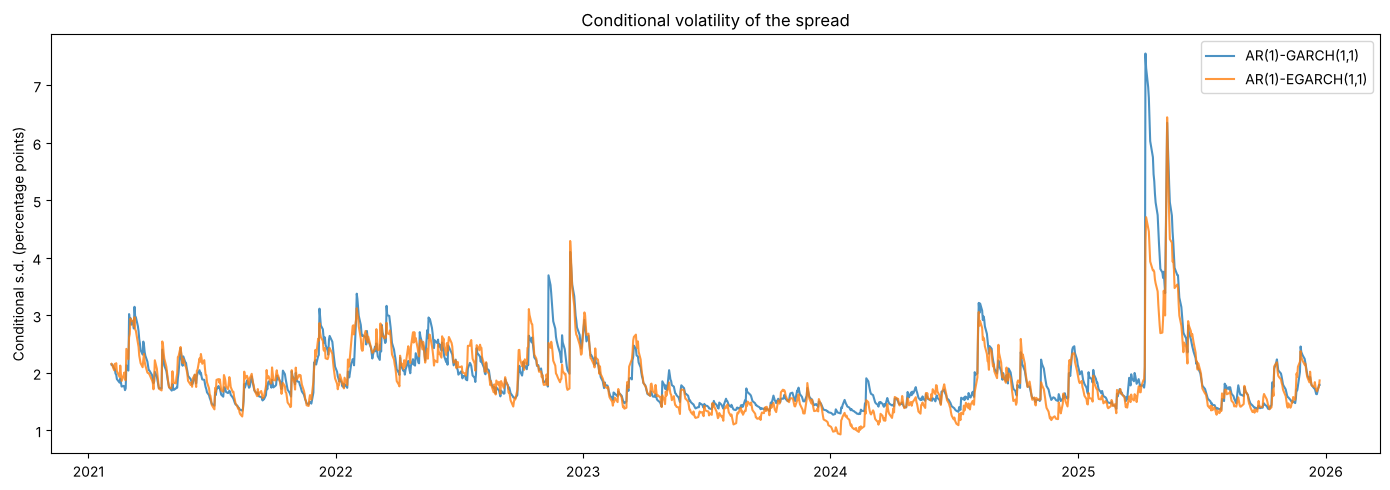

In [6]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(fits['AR(1)-GARCH(1,1)'].conditional_volatility, label='AR(1)-GARCH(1,1)', alpha=0.8)
ax.plot(fits['AR(1)-EGARCH(1,1)'].conditional_volatility, label='AR(1)-EGARCH(1,1)', alpha=0.8)
ax.set_title('Conditional volatility of the spread')
ax.set_ylabel('Conditional s.d. (percentage points)')
ax.legend()
plt.tight_layout()
plt.show()

## 5. Numbers used in Section 9.1 (statistical insights)

In [7]:
g = fits['AR(1)-GARCH(1,1)'].params
e = fits['AR(1)-EGARCH(1,1)'].params
persistence = g['alpha[1]'] + g['beta[1]']
print(f"AR(1) coefficient (GARCH):  {g['Spread[1]']:.4f} -> half-life of a spread shock    = {np.log(0.5)/np.log(g['Spread[1]']):.1f} trading days")
print(f"alpha + beta (GARCH):       {persistence:.4f} -> half-life of a volatility shock = {np.log(0.5)/np.log(persistence):.1f} trading days")
print(f"Degrees of freedom nu:      " + ", ".join(f"{n}: {f.params['nu']:.2f}" for n, f in fits.items()))
print(f"EGARCH sign term gamma:     {e['gamma[1]']:.4f} (p = {fits['AR(1)-EGARCH(1,1)'].pvalues['gamma[1]']:.3f})")

AR(1) coefficient (GARCH):  0.9622 -> half-life of a spread shock    = 18.0 trading days
alpha + beta (GARCH):       0.9721 -> half-life of a volatility shock = 24.5 trading days
Degrees of freedom nu:      AR(1)-GARCH(1,1): 3.10, AR(1)-GJR-GARCH(1,1): 3.19, AR(1)-EGARCH(1,1): 3.31, HAR-GARCH(1,1): 3.14
EGARCH sign term gamma:     0.0734 (p = 0.010)


## Conclusion

AR(1)-EGARCH(1,1) with Student-t errors has the lowest AIC and BIC on both the full and the common sample. All candidates are adequate by the Ljung–Box tests. GJR's extra parameter is not justified by BIC, and the HAR weekly/monthly terms add nothing. Whether EGARCH replaces AR(1)-GARCH(1,1) as the final model is decided by the group (report Section 7.3).